<a href="https://colab.research.google.com/github/Hadeel-93/HW-7/blob/main/HW_7_Q1_B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split

import numpy as np
import time
import copy
import pandas as pd
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.optim as optim

torch.manual_seed(42)
np.random.seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Same preprocessing as Problem 1.a
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

# Set download=True to automatically download the dataset if it's not present
full_train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Same 90/10 training-validation split
train_dataset, val_dataset = random_split(
    full_train_dataset,
    [45000, 5000],
    generator=torch.Generator().manual_seed(42)
)

BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))
print("Data loaders are ready!")

Using device: cpu


100%|██████████| 170M/170M [42:03<00:00, 67.6kB/s]


Training images: 45000
Validation images: 5000
Test images: 10000
Data loaders are ready!


In [ ]:
class CIFAR10_DeepMLP(nn.Module):
    def __init__(self):
        super(CIFAR10_DeepMLP, self).__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            # Hidden layer 1
            nn.Linear(32 * 32 * 3, 512),
            nn.ReLU(),

            # Hidden layer 2
            nn.Linear(512, 256),
            nn.ReLU(),

            # Additional hidden layer 3
            nn.Linear(256, 128),
            nn.ReLU(),

            # Additional hidden layer 4
            nn.Linear(128, 64),
            nn.ReLU(),

            # Output layer
            nn.Linear(64, 10)
        )

    def forward(self, x):
        return self.network(x)


model = CIFAR10_DeepMLP().to(device)

# Count trainable parameters
total_params = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

print(model)
print(f"\nTotal trainable parameters: {total_params:,}")

CIFAR10_DeepMLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=128, bias=True)
    (6): ReLU()
    (7): Linear(in_features=128, out_features=64, bias=True)
    (8): ReLU()
    (9): Linear(in_features=64, out_features=10, bias=True)
  )
)

Total trainable parameters: 1,746,506


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

NUM_EPOCHS = 100
PATIENCE = 7

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

best_val_loss = float("inf")
best_epoch = 0
epochs_without_improvement = 0
best_model_weights = None

print("Maximum epochs:", NUM_EPOCHS)
print("Early stopping patience:", PATIENCE)

Maximum epochs: 100
Early stopping patience: 7


In [ ]:
def calculate_metrics(model, data_loader, criterion):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    average_loss = total_loss / total
    accuracy = 100 * correct / total

    return average_loss, accuracy


start_time = time.perf_counter()

for epoch in range(NUM_EPOCHS):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / total
    epoch_train_accuracy = 100 * correct / total

    # Validation
    epoch_val_loss, epoch_val_accuracy = calculate_metrics(
        model, val_loader, criterion
    )

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    train_accuracies.append(epoch_train_accuracy)
    val_accuracies.append(epoch_val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Train Accuracy: {epoch_train_accuracy:.2f}% | "
        f"Validation Loss: {epoch_val_loss:.4f} | "
        f"Validation Accuracy: {epoch_val_accuracy:.2f}%"
    )

    # Save the best model based on validation loss
    if epoch_val_loss < best_val_loss - 0.0001:
        best_val_loss = epoch_val_loss
        best_epoch = epoch + 1
        best_model_weights = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    # Early stopping
    if epochs_without_improvement >= PATIENCE:
        print(f"\nEarly stopping at epoch {epoch + 1}.")
        break


training_time = time.perf_counter() - start_time

# Restore the best model
if best_model_weights is None:
    raise RuntimeError("Training did not produce a valid model checkpoint.")

model.load_state_dict(best_model_weights)

print("\nTraining completed.")
print("Best epoch:", best_epoch)
print(f"Training time: {training_time:.2f} seconds")

Epoch [1/100] Train Loss: 1.6960 | Train Accuracy: 39.44% | Validation Loss: 1.5636 | Validation Accuracy: 45.00%
Epoch [2/100] Train Loss: 1.4707 | Train Accuracy: 47.82% | Validation Loss: 1.4390 | Validation Accuracy: 49.04%
Epoch [3/100] Train Loss: 1.3496 | Train Accuracy: 52.26% | Validation Loss: 1.3910 | Validation Accuracy: 51.48%
Epoch [4/100] Train Loss: 1.2578 | Train Accuracy: 55.45% | Validation Loss: 1.3926 | Validation Accuracy: 51.14%
Epoch [5/100] Train Loss: 1.1684 | Train Accuracy: 58.49% | Validation Loss: 1.3482 | Validation Accuracy: 53.50%
Epoch [6/100] Train Loss: 1.0877 | Train Accuracy: 61.60% | Validation Loss: 1.3596 | Validation Accuracy: 54.32%
Epoch [7/100] Train Loss: 1.0179 | Train Accuracy: 63.94% | Validation Loss: 1.3888 | Validation Accuracy: 53.06%
Epoch [8/100] Train Loss: 0.9444 | Train Accuracy: 66.66% | Validation Loss: 1.4118 | Validation Accuracy: 53.28%
Epoch [9/100] Train Loss: 0.8781 | Train Accuracy: 68.56% | Validation Loss: 1.4577 | Va

In [7]:
def calculate_metrics(model, data_loader, criterion):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    average_loss = total_loss / total
    accuracy = 100 * correct / total

    return average_loss, accuracy


start_time = time.perf_counter()

for epoch in range(NUM_EPOCHS):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_train_loss = running_loss / total
    epoch_train_accuracy = 100 * correct / total

    # Validation
    epoch_val_loss, epoch_val_accuracy = calculate_metrics(
        model, val_loader, criterion
    )

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    train_accuracies.append(epoch_train_accuracy)
    val_accuracies.append(epoch_val_accuracy)

    print(
        f"Epoch [{epoch + 1}/{NUM_EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Train Accuracy: {epoch_train_accuracy:.2f}% | "
        f"Validation Loss: {epoch_val_loss:.4f} | "
        f"Validation Accuracy: {epoch_val_accuracy:.2f}%"
    )

    # Save the best model based on validation loss
    if epoch_val_loss < best_val_loss - 0.0001:
        best_val_loss = epoch_val_loss
        best_epoch = epoch + 1
        best_model_weights = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1




training_time = time.perf_counter() - start_time

# Restore the best model
if best_model_weights is None:
    raise RuntimeError("Training did not produce a valid model checkpoint.")

model.load_state_dict(best_model_weights)

print("\nTraining completed.")
print("Best epoch:", best_epoch)
print(f"Training time: {training_time:.2f} seconds")

Epoch [1/100] Train Loss: 1.0395 | Train Accuracy: 63.36% | Validation Loss: 1.3660 | Validation Accuracy: 53.66%
Epoch [2/100] Train Loss: 0.9802 | Train Accuracy: 65.13% | Validation Loss: 1.3961 | Validation Accuracy: 54.24%
Epoch [3/100] Train Loss: 0.9263 | Train Accuracy: 66.97% | Validation Loss: 1.4473 | Validation Accuracy: 53.80%
Epoch [4/100] Train Loss: 0.8679 | Train Accuracy: 69.06% | Validation Loss: 1.4824 | Validation Accuracy: 53.24%
Epoch [5/100] Train Loss: 0.8121 | Train Accuracy: 71.27% | Validation Loss: 1.4709 | Validation Accuracy: 54.26%
Epoch [6/100] Train Loss: 0.7541 | Train Accuracy: 72.94% | Validation Loss: 1.5802 | Validation Accuracy: 52.94%
Epoch [7/100] Train Loss: 0.6962 | Train Accuracy: 74.92% | Validation Loss: 1.5836 | Validation Accuracy: 53.16%
Epoch [8/100] Train Loss: 0.6440 | Train Accuracy: 77.12% | Validation Loss: 1.6711 | Validation Accuracy: 54.16%
Epoch [9/100] Train Loss: 0.6017 | Train Accuracy: 78.62% | Validation Loss: 1.7825 | Va

In [8]:
# Evaluate the restored best model on the training dataset
final_train_loss, final_train_accuracy = calculate_metrics(
    model, train_loader, criterion
)

# Evaluate on the independent test dataset
test_loss, test_accuracy = calculate_metrics(
    model, test_loader, criterion
)

print("\n========== Problem 1.b Results ==========")
print(f"Best epoch: {best_epoch}")
print(f"Training time: {training_time:.2f} seconds")
print(f"Training loss: {final_train_loss:.4f}")
print(f"Training accuracy: {final_train_accuracy:.2f}%")
print(f"Test loss: {test_loss:.4f}")
print(f"Evaluation accuracy: {test_accuracy:.2f}%")
print(f"Trainable parameters: {total_params:,}")


========== Problem 1.b Results ==========
Best epoch: 5
Training time: 2305.86 seconds
Training loss: 1.0343
Training accuracy: 63.33%
Test loss: 1.3429
Evaluation accuracy: 53.15%
Trainable parameters: 1,746,506


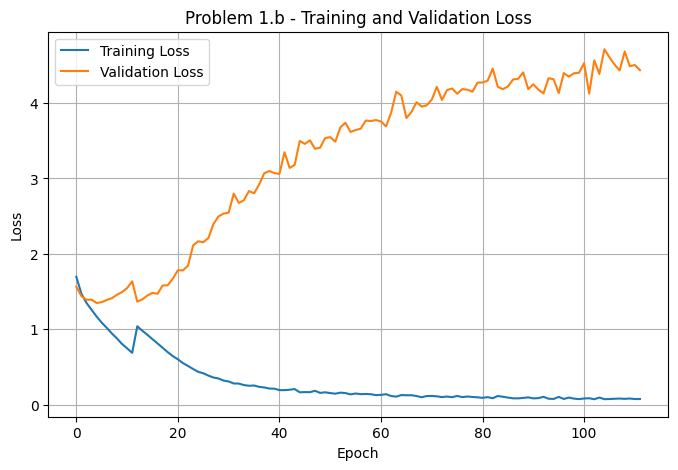

In [9]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Problem 1.b - Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

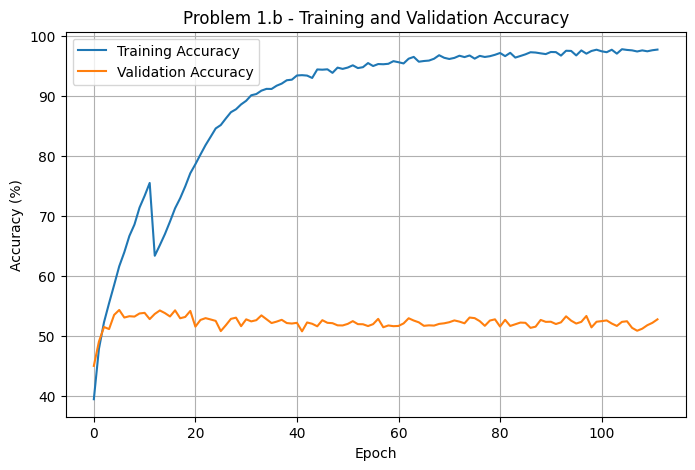

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Problem 1.b - Training and Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
torch.save(model.state_dict(), "cifar10_deep_mlp.pth")

results_1b = {
    "Best Epoch": best_epoch,
    "Training Time (seconds)": training_time,
    "Training Loss": final_train_loss,
    "Training Accuracy (%)": final_train_accuracy,
    "Test Loss": test_loss,
    "Evaluation Accuracy (%)": test_accuracy,
    "Trainable Parameters": total_params
}

results_df = pd.DataFrame([results_1b])
display(results_df)

results_df.to_csv("problem_1b_results.csv", index=False)

print("Model and results saved successfully.")

,Best Epoch,Training Time (seconds),Training Loss,Training Accuracy (%),Test Loss,Evaluation Accuracy (%),Trainable Parameters
0,5,2305.861105,1.034339,63.331111,1.342893,53.15,1746506


Model and results saved successfully.


In [12]:
# Replace these None values with your actual Problem 1.a results
baseline_1a = {
    "Training Time (seconds)": None,
    "Training Loss": None,
    "Training Accuracy (%)": None,
    "Evaluation Accuracy (%)": None,
    "Trainable Parameters": 1707274
}

comparison = pd.DataFrame({
    "Metric": [
        "Training Time (seconds)",
        "Training Loss",
        "Training Accuracy (%)",
        "Evaluation Accuracy (%)",
        "Trainable Parameters"
    ],
    "Problem 1.a - Baseline": list(baseline_1a.values()),
    "Problem 1.b - Deeper Network": [
        training_time,
        final_train_loss,
        final_train_accuracy,
        test_accuracy,
        total_params
    ]
})

display(comparison)

,Metric,Problem 1.a - Baseline,Problem 1.b - Deeper Network
0,Training Time (seconds),NaN,2.305861e+03
1,Training Loss,NaN,1.034339e+00
2,Training Accuracy (%),NaN,6.333111e+01
3,Evaluation Accuracy (%),NaN,5.315000e+01
4,Trainable Parameters,1707274.0,1.746506e+06
